# How flooding affects public and community services in Oakland

Flooding does the most harm where people depend on a place: a dialysis clinic patients must reach every few
days, a senior center, a library used as a cooling or warming center, a Head Start site, a fire station.
This notebook asks two questions:

1. **Today (citywide):** which services sit in areas that already flood when it rains? We use FloodWatch's
   overall risk for the hex each site is in, and count OAK 311 flood reports within 250 m (about two blocks), 2013–2026.
2. **With sea-level rise (West Oakland study area):** at what rise does a service's building flood, does its
   nearest road become impassable, and how much of the street network within a 5-minute walk (400 m) goes under water?

The numbers come from `pipeline/11_services.py` (run by `pipeline/run_all.sh`), which writes
`data/processed/floodwatch/services.csv`. Sources and assumptions are listed at the end.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve().parents[1]
FW = ROOT / "data" / "processed" / "floodwatch"
OUT = ROOT / "oakland-flood-vulnerability" / "outputs"
svc = pd.read_csv(FW / "services.csv")
summary = json.loads((FW / "services_summary.json").read_text())
LABEL = {"hospital": "Hospitals", "nursing_home": "Nursing homes", "dialysis": "Dialysis clinics",
         "fire_station": "Fire stations", "school": "Public schools", "head_start": "Head Start sites",
         "library": "Library branches", "senior_center": "Senior centers", "rec_center": "Rec centers and pools",
         "bart": "BART stations"}
svc["type"] = svc.ftype.map(LABEL)
svc["high_risk"] = svc.risk.isin(["High", "Very high"])
print(f"{len(svc)} services in Oakland; 311 flood reports through {summary['reports_through']}")
svc.groupby("category").type.value_counts().rename("sites").to_frame()

257 services in Oakland; 311 flood reports through 2026-11-15


sites
category            type                        
Community           Rec centers and pools     28
                    Library branches          18
                    Senior centers             8
Education and youth Public schools           118
                    Head Start sites          17
Emergency           Fire stations             26
Health and care     Nursing homes             18
                    Dialysis clinics          11
                    Hospitals                  5
Transit             BART stations              8

## 1. Today: services in areas that already flood
"High risk" means the site's hex is in the top 30% of Oakland on FloodWatch's overall risk, so if services were
spread evenly, about **30%** of each type would be there. Anything well above 30% is concentrated in risky areas.

In [2]:
t = (svc.groupby(["category", "type"])
     .agg(sites=("site_id", "size"), in_high_risk=("high_risk", "sum"),
          median_reports_250m=("flood_reports_250m", "median"),
          sites_10plus_reports=("flood_reports_250m", lambda s: int((s >= 10).sum())),
          high_risk_and_high_svi=("high_risk", lambda s: int((s & (svc.loc[s.index, "svi"] >= 0.8)).sum())))
     .reset_index())
t["share_high_risk"] = (t.in_high_risk / t.sites).round(2)
t.sort_values("share_high_risk", ascending=False).set_index(["category", "type"])

sites  in_high_risk  \
category            type                                         
Education and youth Head Start sites          17            16   
Health and care     Nursing homes             18            14   
Transit             BART stations              8             6   
Health and care     Dialysis clinics          11             7   
                    Hospitals                  5             3   
Community           Rec centers and pools     28            15   
Education and youth Public schools           118            64   
Community           Library branches          18             8   
Emergency           Fire stations             26            11   
Community           Senior centers             8             3   

                                           median_reports_250m  \
category            type                                         
Education and youth Head Start sites                      17.0   
Health and care     Nursing homes                         11.0   
Transit             BART stations                         23.0   
Health and care     Dialysis clinics                      19.0   
                    Hospitals                              6.0   
Community           Rec centers and pools                 10.5   
Education and youth Public schools                         8.0   
Community           Library branches                      20.0   
Emergency           Fire stations                         12.5   
Community           Senior centers                        11.0   

                                           sites_10plus_reports  \
category            type                                          
Education and youth Head Start sites                         13   
Health and care     Nursing homes                            13   
Transit             BART stations                             6   
Health and care     Dialysis clinics                          9   
                    Hospitals                                 0   
Community           Rec centers and pools                    15   
Education and youth Public schools                           45   
Community           Library branches                         13   
Emergency           Fire stations                            15   
Community           Senior centers                            4   

                                           high_risk_and_high_svi  \
category            type                                            
Education and youth Head Start sites                            9   
Health and care     Nursing homes                               8   
Transit             BART stations                               3   
Health and care     Dialysis clinics                            3   
                    Hospitals                                   0   
Community           Rec centers and pools                       7   
Education and youth Public schools                             36   
Community           Library branches                            2   
Emergency           Fire stations                               3   
Community           Senior centers                              1   

                                           share_high_risk  
category            type                                    
Education and youth Head Start sites                  0.94  
Health and care     Nursing homes                     0.78  
Transit             BART stations                     0.75  
Health and care     Dialysis clinics                  0.64  
                    Hospitals                         0.60  
Community           Rec centers and pools             0.54  
Education and youth Public schools                    0.54  
Community           Library branches                  0.44  
Emergency           Fire stations                     0.42  
Community           Senior centers                    0.38

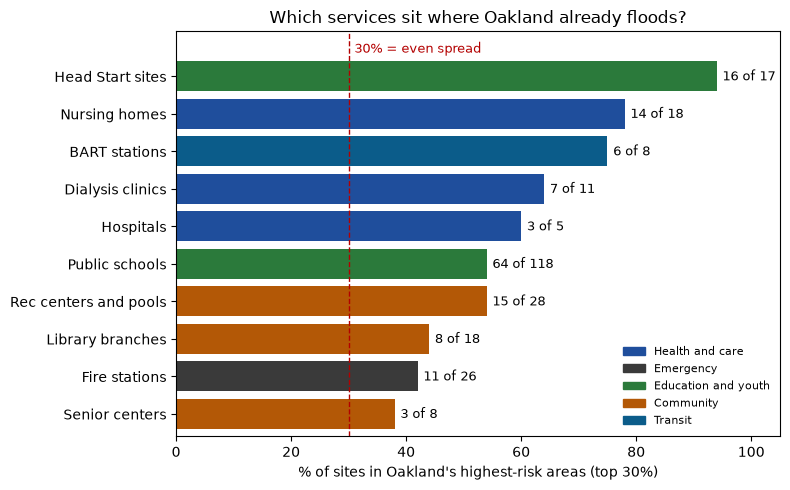

In [3]:
o = t.sort_values("share_high_risk")
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"Health and care": "#1f4e9c", "Emergency": "#3a3a3a", "Education and youth": "#2b7a3b",
          "Community": "#b35806", "Transit": "#0b5c8a"}
ax.barh(o.type, o.share_high_risk * 100, color=[colors[c] for c in o.category])
ax.axvline(30, color="#b30000", ls="--", lw=1)
ax.text(31, len(o) - 0.45, "30% = even spread", color="#b30000", fontsize=9, va="bottom")
ax.set_ylim(-0.6, len(o) + 0.2)
for y, (v, n, s) in enumerate(zip(o.share_high_risk, o.in_high_risk, o.sites)):
    ax.text(v * 100 + 1, y, f"{n} of {s}", va="center", fontsize=9)
ax.set_xlabel("% of sites in Oakland's highest-risk areas (top 30%)")
ax.set_xlim(0, 105)
ax.set_title("Which services sit where Oakland already floods?")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
ax.legend(handles, colors.keys(), loc="lower right", fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(OUT / "services_today.png", dpi=150); plt.show()

### Community services with the most flooding around them

In [4]:
comm = svc[svc.category.isin(["Community", "Education and youth", "Health and care"]) & svc.high_risk]
comm.sort_values("flood_reports_250m", ascending=False)[
    ["type", "name", "address", "risk", "svi", "flood_reports_250m"]].head(15).reset_index(drop=True)

,type,name,address,risk,svi,flood_reports_250m
0,Public schools,Franklin Elementary,915 Foothill Blvd.,High,0.8454,59
1,Head Start sites,Head Start: Frank G. M,274 12th Street,Very high,0.8374,51
2,Public schools,Lincoln Elementary,225 11th St.,Very high,0.8374,48
3,Rec centers and pools,Lincoln Square,250 - 10th Street,Very high,0.8374,45
4,Library branches,Elmhurst Branch,1427 88th Avenue,Very high,0.7323,42
5,Public schools,Alternatives in Action,6221 East 17th St.,Very high,0.9205,41
6,Public schools,Greenleaf,6328 East 17th St.,Very high,0.8228,41
7,Library branches,African American Museum and Library at Oakland,659 14th Street,High,0.5915,37
8,Library branches,Asian Branch,"388 9th Street, Suite 190",Very high,0.8374,36
9,Library branches,"Martin Luther King, Jr. Branch",6833 International Boulevard,High,0.6985,32


## 2. With sea-level rise: West Oakland study area
Three effects, from mildest to most direct:
- **Streets around it flood:** share of local street length within 400 m that is impassable (> 15 cm of water).
- **Nearest road floods:** the closest non-freeway road (within 200 m) is impassable.
- **The site floods:** its building footprint (or its own spot, if it has no building) is under water.

In [5]:
area = svc[svc.in_study_area]
rows = []
for ft in range(6):
    sid = f"{ft}ft"
    rows.append({"sea-level rise": f"+{ft} ft", "services in study area": len(area),
                 "site floods": int(area[f"site_flooded_{sid}"].sum()),
                 "nearest road impassable": int(area[f"access_lost_{sid}"].sum()),
                 ">= 25% of nearby streets impassable": int((area[f"streets_impassable_{sid}"] >= 0.25).sum()),
                 ">= 10% of nearby streets impassable": int((area[f"streets_impassable_{sid}"] >= 0.10).sum())})
pd.DataFrame(rows).set_index("sea-level rise")

,services in study area,site floods,nearest road impassable,>= 25% of nearby streets impassable,>= 10% of nearby streets impassable
sea-level rise,,,,,
+0 ft,60,0,0,0,0
+1 ft,60,0,0,0,0
+2 ft,60,0,0,0,0
+3 ft,60,0,0,0,0
+4 ft,60,1,1,0,0
+5 ft,60,1,1,5,11


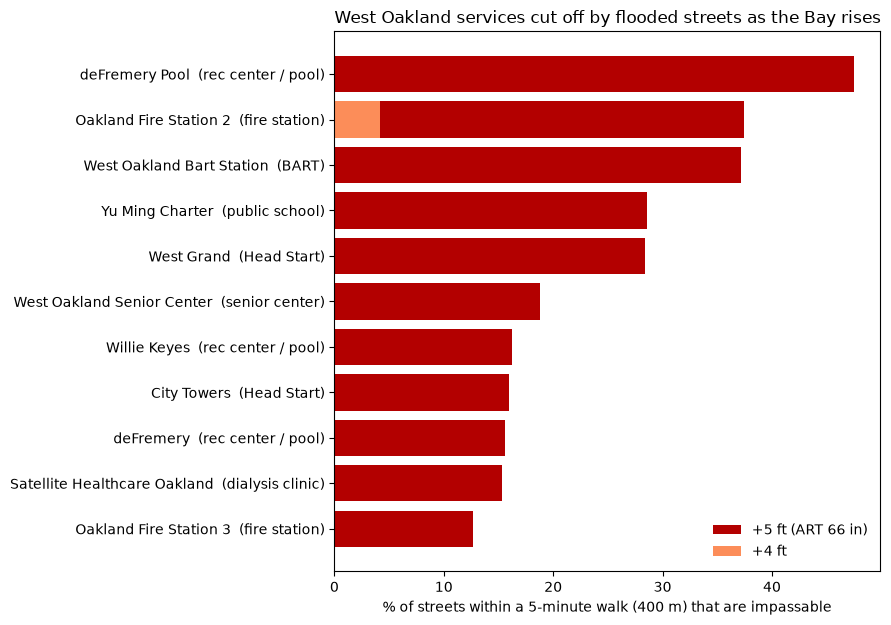

,type,name,site_flood_ft,access_loss_ft,streets_impassable_4ft,streets_impassable_5ft,risk,flood_reports_250m
0,Rec centers and pools,deFremery Pool,NaN,NaN,0.000,0.475,Moderate,5
1,Fire stations,Oakland Fire Station 2,4.0,4.0,0.042,0.374,Moderate,12
2,BART stations,West Oakland Bart Station,NaN,NaN,0.000,0.372,Moderate,10
3,Public schools,Yu Ming Charter,NaN,NaN,0.000,0.286,High,2
4,Head Start sites,Head Start: West Grand,NaN,NaN,0.000,0.284,High,19
5,Senior centers,West Oakland Senior Center,NaN,NaN,0.000,0.188,Moderate,3
6,Rec centers and pools,Willie Keyes,NaN,NaN,0.000,0.162,High,10
7,Head Start sites,Head Start: City Towers,NaN,NaN,0.000,0.160,High,14
8,Rec centers and pools,deFremery,NaN,NaN,0.000,0.156,Moderate,5
9,Dialysis clinics,Satellite Healthcare Oakland,NaN,NaN,0.000,0.153,Moderate,20


In [6]:
ONE = {"hospital": "hospital", "nursing_home": "nursing home", "dialysis": "dialysis clinic",
       "fire_station": "fire station", "school": "public school", "head_start": "Head Start",
       "library": "library", "senior_center": "senior center", "rec_center": "rec center / pool", "bart": "BART"}
hit = area[area.streets_impassable_5ft >= 0.10].sort_values("streets_impassable_5ft")
fig, ax = plt.subplots(figsize=(9, 0.45 * len(hit) + 1.4))
labels = hit.name.str.replace("Head Start: ", "", regex=False) + "  (" + hit.ftype.map(ONE) + ")"
for ft, c in [(5, "#b30000"), (4, "#fc8d59")]:
    ax.barh(labels, hit[f"streets_impassable_{ft}ft"] * 100,
            color=c, label=f"+{ft} ft" + (" (ART 66 in)" if ft == 5 else ""))
ax.set_xlabel("% of streets within a 5-minute walk (400 m) that are impassable")
ax.set_title("West Oakland services cut off by flooded streets as the Bay rises", loc="left")
ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(OUT / "services_slr.png", dpi=150); plt.show()
hit[["type", "name", "site_flood_ft", "access_loss_ft", "streets_impassable_4ft", "streets_impassable_5ft",
     "risk", "flood_reports_250m"]].iloc[::-1].reset_index(drop=True)

## What this shows
**Today, the services people can least do without are concentrated where Oakland already floods.**
With an even spread, about 30% of each type would sit in the highest-risk areas. Instead:
- **16 of 17 Head Start sites** (94%), **14 of 18 nursing homes** (78%), **6 of 8 BART stations** (75%) and
  **7 of 11 dialysis clinics** (64%) are in high or very high risk areas. 9 Head Start sites and 8 nursing homes are
  also in the most socially vulnerable tracts (SVI ≥ 0.8).
- Libraries and BART stations have a median of about **20 flood reports within two blocks**, mostly because they are
  downtown and in the flatlands.
- The worst cluster is **downtown and Chinatown around 9th–12th Streets**: Lincoln Elementary, Lincoln Square
  Recreation Center, the Asian Branch library and a Head Start site each have 36–51 flood reports within two blocks.
  Franklin Elementary (Foothill Blvd) has the most: 59.
- Senior centers (3 of 8) and fire stations (11 of 26) are close to an even spread.

**Sea-level rise mostly cuts services off before it floods them.** In the West Oakland study area (60 services):
- Up to **+3 ft**, no service's building or nearest road floods.
- At **+4 ft**, only **Oakland Fire Station 2** (Jack London waterfront) floods, along with its road.
- At **+5 ft (ART 66 in)**, still no other building floods, but **11 services lose at least 10% of the streets within a
  5-minute walk, and 5 lose at least 25%**: deFremery Pool (48%), Fire Station 2 (37%), West Oakland BART (37%),
  Yu Ming Charter school (29%) and Head Start West Grand (28%). These are services that residents without cars
  reach on foot or by bus.

**Double exposure.** Head Start West Grand (19 flood reports within two blocks today, 28% of nearby streets impassable at
+5 ft) and Satellite Healthcare's dialysis clinic (20 reports today, 15% at +5 ft) already flood in storms and would
be harder to reach with sea-level rise. They are concrete examples for the combined story.

## Sources and assumptions
- **Sources:** CDPH licensed facilities (active hospitals, skilled nursing, chronic dialysis), Oakland Fire Department
  stations, California Dept. of Education schools 2024–25 (active), BART stations, and City of Oakland open data for
  library branches, senior centers, Head Start sites and Parks & Rec recreation centers and pools.
- **The city's library, senior center, Head Start and Parks & Rec datasets were last updated in 2013** (the latest
  published). A few of those sites may have moved or closed; spot-check any site before naming it in a presentation.
  Some names are cut off in the source data (for example "Head Start: Frank G. M", at 274 12th Street).
- **311 reports** reflect who reports flooding, not only where it happens. Counts within 250 m include reports
  on nearby streets, not necessarily at the site.
- **Access** looks at roads only, with still water at high tide (no rain, storm surge or traffic). A site whose
  nearest road floods may still be reachable another way; a site with many flooded streets around it is harder
  to reach on foot, by bus or by ambulance.
- **Sea-level rise** results cover the West Oakland study area only (60 of the 257 services).